In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('data/website-task-bank.csv', sep=';', encoding='latin1')

In [3]:
df.columns

Index(['Timestamp', 'Domain', 'Region', 'Country',
       'Website or organization name', 'Starting URL', 'Website language',
       'Task Goal', 'How did you complete this task?',
       'Provide screenshot evidence of you completing the task'],
      dtype='object')

In [4]:
from data_profiling import ProfileReport

profile = ProfileReport(df.loc[:, ~df.columns.isin(['Task Goal', 'How did you complete this task?',
       'Provide screenshot evidence of you completing the task'])], title="Profiling Report")

/Users/juan/Local/research-projects/triple-A/notebooks/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
profile.to_file("profile.html")

/Users/juan/Local/research-projects/triple-A/notebooks/venv/lib/python3.11/site-packages/data_profiling/utils/dataframe.py:137: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={"index": "df_index"}, inplace=True)
Summarize dataset:  17%|█▋        | 2/12 [00:00<00:00, 67.05it/s, Describe variable: Website language]/Users/juan/Local/research-projects/triple-A/notebooks/venv/lib/python3.11/site-packages/data_profiling/model/typeset_relations.py:118: FutureWarning: Parsed string "2026/10/14 6:49:22 AM EST" included an un-recognized timezone "EST". Dropping unrecognized timezones is deprecated; in a future version this will raise. Instead pass the string without the timezone, then use .tz_localize to convert to a recognized timezone.
  return pd.to_datetime(series, format="mixed")
/Users/jua

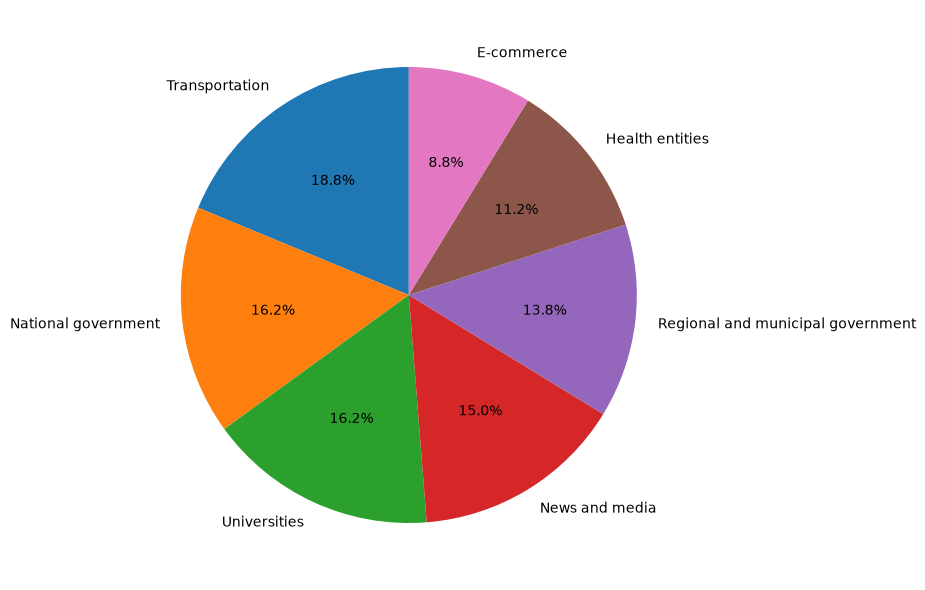

In [6]:
import matplotlib.pyplot as plt

domains = df.groupby('Domain').size().sort_values(ascending=False)
domains.plot(
    kind='pie',
    figsize=(12, 6),
    labels=domains.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.ylabel('')
plt.tight_layout()
plt.show()

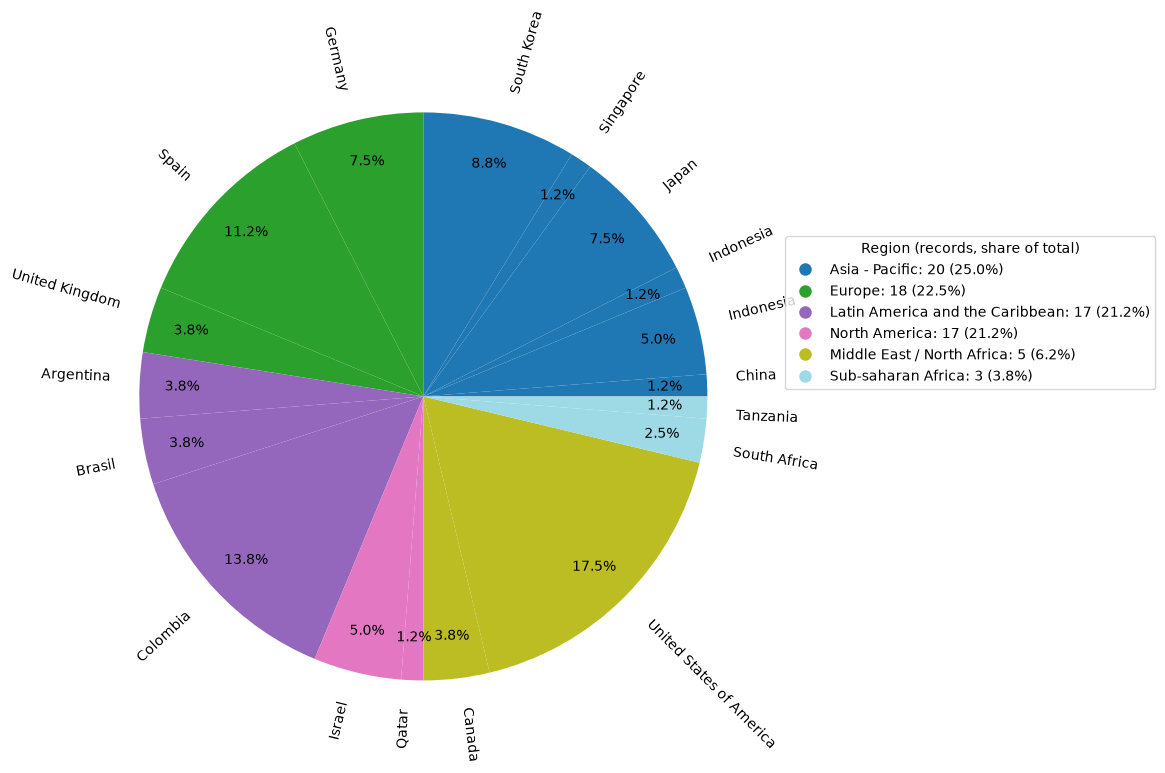

In [7]:
import numpy as np

regions = df.groupby('Region').size().sort_values(ascending=False)

country_counts = (
    df.groupby(['Region', 'Country'])
      .size()
      .reset_index(name='Count')
)

country_counts['RegionOrder'] = pd.Categorical(
    country_counts['Region'],
    categories=regions.index,
    ordered=True
)

country_counts = country_counts.sort_values(
    ['RegionOrder', 'Count', 'Country'],
    ascending=[True, False, True]
)

region_colors = dict(zip(
    regions.index,
    plt.cm.tab20(np.linspace(0, 1, len(regions)))
))

country_colors = [
    region_colors[region]
    for region in country_counts['Region']
]

total_count = country_counts['Count'].sum()

region_legend_labels = [
    f'{region}: {count} ({count / total_count:.1%})'
    for region, count in regions.items()
]

region_handles = [
    plt.Line2D(
        [0],
        [0],
        marker='o',
        color='w',
        markerfacecolor=region_colors[region],
        markersize=10,
        label=label
    )
    for region, label in zip(regions.index, region_legend_labels)
]

country_counts = (
    df.groupby(['Region', 'Country'])
      .size()
      .reset_index(name='Count')
)

fig, ax = plt.subplots(figsize=(12, 8))

ax.pie(
    country_counts['Count'],
    labels=country_counts['Country'],
    colors=country_colors,
    startangle=0,
    autopct='%1.1f%%',
    labeldistance=1.1,
    rotatelabels=True,
    pctdistance=0.85,
)

ax.legend(
    handles=region_handles,
    title='Region (records, share of total)',
    loc='lower left',
    bbox_to_anchor=(1, 0.5)
)
plt.tight_layout(rect=[0, 0, 0.8, 1])
plt.show()


/var/folders/05/h_xl6mtd7h1dhnqt5jbnbycc0000gn/T/ipykernel_19714/1846181516.py:7: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/juan/Local/research-projects/triple-A/notebooks/venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


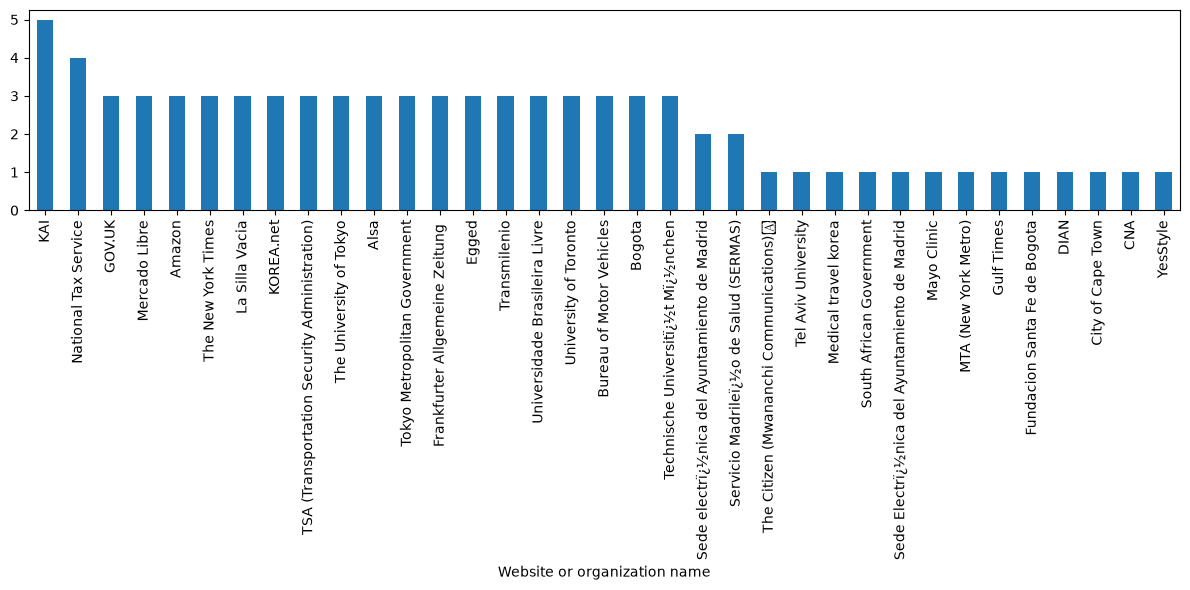

In [8]:
organization = df.groupby('Website or organization name').size().sort_values(ascending=False)
organization.plot(
    kind='bar',
    figsize=(12, 6),
)

plt.tight_layout()
plt.show()

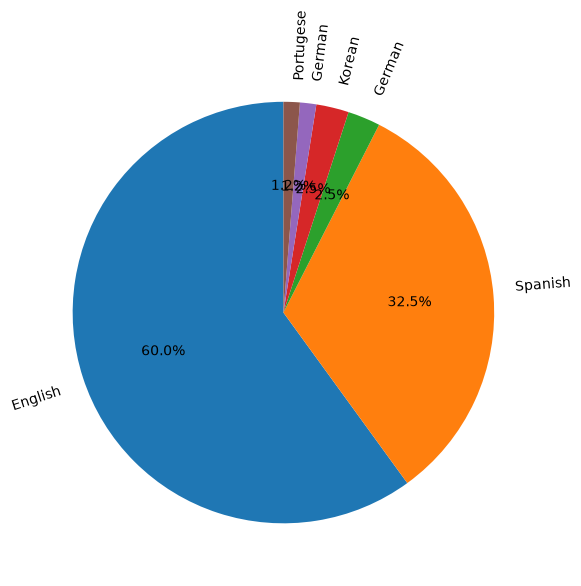

In [10]:
languages = df.groupby('Website language').size().sort_values(ascending=False)
languages.plot(
    kind='pie',
    figsize=(12, 6),
    labels=languages.index,
    autopct='%1.1f%%',
    startangle=90,
    rotatelabels=True,
)
plt.ylabel('')
plt.tight_layout()
plt.show()

In [17]:
examples = df.get(['Starting URL', 'Task Goal'])
examples


,Starting URL,Task Goal
0,https://www.transmilenio.gov.co,"Starting from the Transmileio homepage, which ..."
1,https://www.tsa.gov/,"Starting from the TSA homepage, find the eleme..."
2,https://www.in.gov/bmv/,The task goal is to estimate your fees and tax...
3,https://bogota.gov.co/en,"Starting from the official bogota government, ..."
4,https://www.lasillavacia.com/,"Starting from La Silla Vacï¿½aï¿½s homepage, w..."
...,...,...
75,https://www.nts.go.kr/english/main.do,"On this website, starting from National Tax Se..."
76,https://www.gulf-times.com/homepage-mobile,"Starting from the Gulf Times mobile homepage, ..."
77,https://sede.madrid.es/portal/site/tramites,Start on the Madrid Sede Electrï¿½nica Ciudada...
78,https://sede.madrid.es/portal/site/tramites,Start on the Madrid Sede Electrï¿½nica Ciudada...


In [18]:
%pip install openai

  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 27.5 MB/s  0:00:00
Using cached anyio-4.15.1-py3-none-any.whl (132 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [openai]2m7/8 [openai]
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# import os
# import pandas as pd
# from openai import OpenAI

# client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])

# examples = (
#     df[["Starting URL", "Task Goal"]]
#     .dropna()
#     .reset_index(drop=True)
# )

# rubric = """
# Evaluate whether the task follows this structure:

# 1. Starting point: Where does the participant begin?
# 2. Interaction constraint: Is a required navigation method specified, or is a strategy prohibited?
# 3. Specific goal: What information or outcome must the participant find or achieve?
# 4. Required output: What exactly must be reported or done to demonstrate success?

# The intended format is:

# "On this website, starting from [starting page] and [specified interaction condition],
# find [specific information or complete a specific goal]. Report [exact answer required]
# and [any additional evidence or detail needed]."
# """

# def evaluate_task(row):
#     prompt = f"""
# {rubric}

# Starting URL:
# {row["Starting URL"]}

# Task Goal:
# {row["Task Goal"]}

# Evaluate whether the task is clearly and specifically defined for this website.
# Your response must contain exactly two sentences:
# - Sentence 1: State whether the task is well-defined and website-specific.
# - Sentence 2: Identify the most important missing, unclear, or incorrect element.
# Do not use bullet points, headings, or additional sentences.
# """

#     response = client.responses.create(
#         model="gpt-4.1-nano",
#         input=prompt,
#         max_output_tokens=150,
#     )

#     return response.output_text.strip()

# examples["OpenAI Evaluation"] = examples.apply(evaluate_task, axis=1)
# examples.head()

,Starting URL,Task Goal,OpenAI Evaluation
0,https://www.transmilenio.gov.co,"Starting from the Transmileio homepage, which ...",The task is somewhat well-defined as it specif...
1,https://www.tsa.gov/,"Starting from the TSA homepage, find the eleme...",The task is moderately well-defined and specif...
2,https://www.in.gov/bmv/,The task goal is to estimate your fees and tax...,The task is somewhat well-defined and website-...
3,https://bogota.gov.co/en,"Starting from the official bogota government, ...",The task is somewhat well-defined but not full...
4,https://www.lasillavacia.com/,"Starting from La Silla Vacï¿½aï¿½s homepage, w...","The task is well-defined and website-specific,..."


In [ ]:
# examples.to_csv('examples.csv')